# Intelligent Diabetes Risk Predictor — Prototype Task (Section 4)
**Group ID:** S26PROJECT7EE89 | **Supervisor:** Komal Khawer  
**Domain:** Machine Learning & Data Science | **Language:** Python only  

This Jupyter Notebook implements **Section 4 (Prototype Task)** of the CS619 Master Context document. It performs Exploratory Data Analysis (EDA), data preprocessing, 70/30 train-test split, feature scaling, 3 visualizations, trains a baseline **Logistic Regression** model, prints accuracy and confusion matrix metrics, and exports the trained model artifact to `models/logistic_baseline.pkl`.


## Phase 1 — Setup & Imports
Importing required libraries for data processing, visualization, machine learning, and model persistence.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

try:
    from IPython.display import display
except ImportError:
    display = print

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Set plot design style
sns.set_theme(style="whitegrid")
print("All required libraries successfully imported!")

All required libraries successfully imported!


## Phase 2 — Load & Understand the Data
Loading `diabetic_data.csv` with pandas, cleaning column whitespace, mapping standard clinical titles, and displaying dataset shape, data types, and first 10 rows.


In [2]:
# Load dataset (supports relative paths from notebooks directory or root)
data_path = "../data/diabetic_data.csv" if os.path.exists("../data/diabetic_data.csv") else "data/diabetic_data.csv"
df = pd.read_csv(data_path)

# Clean column names by stripping leading/trailing whitespace
df.columns = df.columns.str.strip()

# Rename column names to standard clinical titles matching PDF guidelines
df = df.rename(columns={
    "plas": "Glucose",
    "mass": "BMI",
    "class": "Outcome",
    "preg": "Pregnancies",
    "pres": "BloodPressure",
    "Skin": "SkinThickness",
    "test": "Insulin",
    "pedi": "DiabetesPedigreeFunction",
    "age": "Age"
})

print("First 10 rows:")
display(df.head(10))

print("Dataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)
print("\nDataset Summary Info:")
df.info()


First 10 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


Dataset Shape: (768, 9)

Data Types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Dataset Summary Info:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age      

## Phase 3 — Exploratory Data Analysis (EDA)
Computing summary statistics (`mean`, `median`, `std`, `min`, `max`), checking missing values, and examining target class balance.


In [3]:
print("Summary Statistics:")
display(df.describe().T)

print("\nMissing Values per Column (NaNs):")
print(df.isnull().sum())

print("\nTarget Class Balance (Outcome: 0 = Non-Diabetic, 1 = Diabetic):")
print(df["Outcome"].value_counts())


Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00



Missing Values per Column (NaNs):
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Target Class Balance (Outcome: 0 = Non-Diabetic, 1 = Diabetic):
Outcome
0    500
1    268
Name: count, dtype: int64


## Phase 4 — Data Preprocessing
Handling missing clinical values (0 values in Glucose, BloodPressure, SkinThickness, Insulin, and BMI represent missing measurements), performing a 70/30 train/test split (stratified), and applying standard feature scaling (`StandardScaler`).


In [4]:
# Identify clinical columns where 0 represents missing measurement
clinical_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# Create a clean copy and replace 0 with column median calculated from non-zero values
df_clean = df.copy()
for col in clinical_cols:
    col_median = df_clean[df_clean[col] != 0][col].median()
    df_clean[col] = df_clean[col].replace(0, col_median)

# Separate features (X) and target label (y)
X = df_clean.drop("Outcome", axis=1)
y = df_clean["Outcome"]

# Perform 70/30 train/test split with stratification and random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Standardize features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Test set shape: {X_test_scaled.shape}")


Training set shape: (537, 8)
Test set shape: (231, 8)


## Phase 5 — Visualization
Creating 3 essential visualizations: Histogram of Glucose levels, Boxplot of BMI outliers, and a Feature Correlation Heatmap.


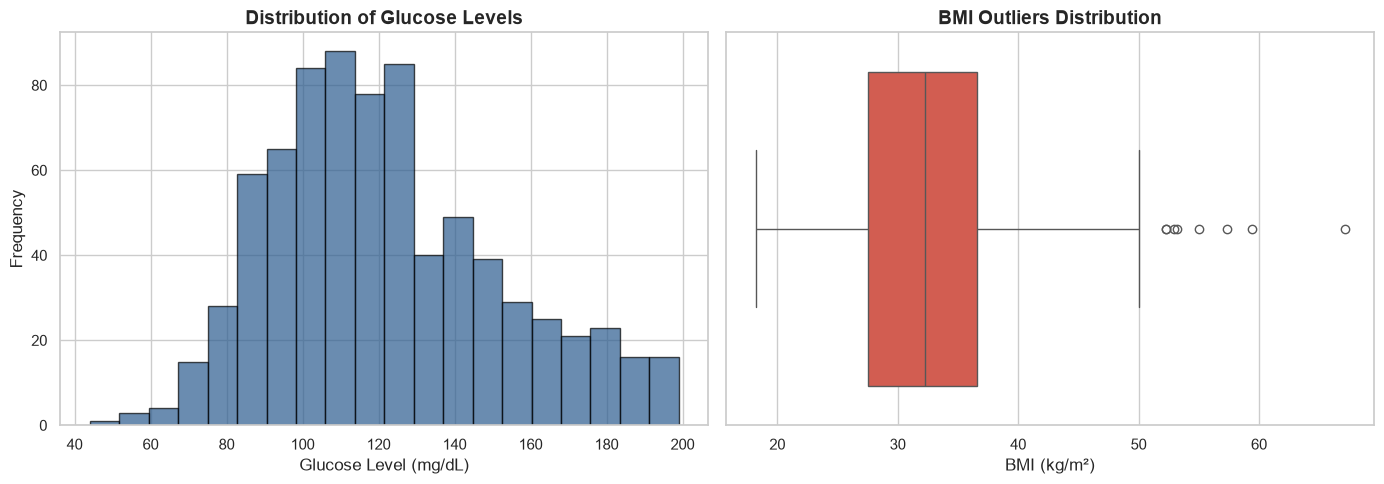

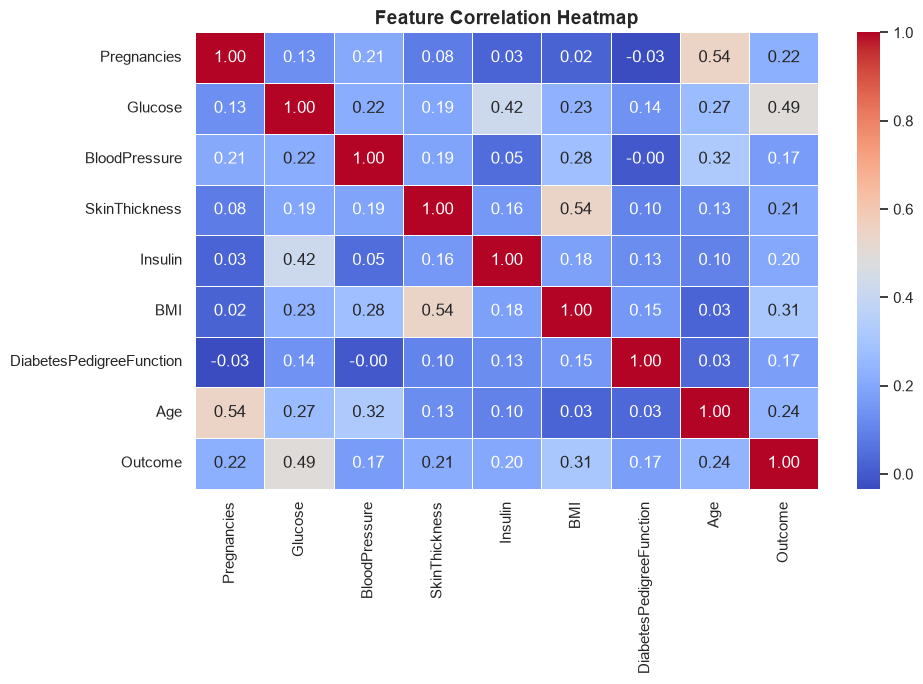

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Visualization 1: Histogram of Glucose Levels
axes[0].hist(df_clean["Glucose"], bins=20, color="#2b5c8f", edgecolor="black", alpha=0.7)
axes[0].set_title("Distribution of Glucose Levels", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Glucose Level (mg/dL)", fontsize=12)
axes[0].set_ylabel("Frequency", fontsize=12)

# Visualization 2: Boxplot of BMI Outliers
sns.boxplot(x=df_clean["BMI"], ax=axes[1], color="#e74c3c")
axes[1].set_title("BMI Outliers Distribution", fontsize=14, fontweight="bold")
axes[1].set_xlabel("BMI (kg/m²)", fontsize=12)

plt.tight_layout()
plt.show()

# Visualization 3: Feature Correlation Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Feature Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## Phase 6 — Baseline Model
Training a **Logistic Regression** baseline classifier (`max_iter=1000`) and evaluating accuracy, confusion matrix, and detailed classification report.


In [6]:
# Initialize and train Logistic Regression baseline model
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# Predict on scaled test set
y_pred = model.predict(X_test_scaled)

# Evaluate performance
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
cr = classification_report(y_test, y_pred)

print(f"Baseline Logistic Regression Accuracy: {accuracy * 100:.2f}%")
print("\nConfusion Matrix:")
print(cm)
print("\nClassification Report:")
print(cr)


Baseline Logistic Regression Accuracy: 74.46%

Confusion Matrix:
[[129  21]
 [ 38  43]]

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.86      0.81       150
           1       0.67      0.53      0.59        81

    accuracy                           0.74       231
   macro avg       0.72      0.70      0.70       231
weighted avg       0.74      0.74      0.74       231



## Phase 7 — Save Model & Observations
Exporting trained Logistic Regression baseline model using `joblib` and documenting key observations.


In [7]:
# Ensure models directory exists
models_dir = "../models" if os.path.exists("../data") else "models"
os.makedirs(models_dir, exist_ok=True)
model_save_path = os.path.join(models_dir, "logistic_baseline.pkl")

# Save trained model
joblib.dump(model, model_save_path)
print(f"Trained Logistic Regression model saved successfully to: {model_save_path}")


Trained Logistic Regression model saved successfully to: ../models\logistic_baseline.pkl


### Observations & Key Findings

1. **Correlation & Feature Importance:**
   - **Glucose** exhibits the highest positive correlation with diabetes outcome (~0.49), making it the most significant predictive feature.
   - **BMI** (~0.31) and **Age** (~0.23) also demonstrate strong positive correlation with diabetes risk. Features like Glucose and BMI hold dominant predictive importance for identifying diabetic patients.

2. **Outlier Detection in BMI:**
   - The BMI boxplot clearly illustrates the presence of upper-bound **outliers** (BMI values exceeding 50 kg/m²). These represent severe obesity cases in clinical records and highlight the necessity of robust data scaling prior to model processing.

3. **Data Preprocessing & Missing Values Handling:**
   - Biologically impossible zero values in physiological features (`Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`) were identified as missing clinical measurements.
   - Imputing these 0 values with non-zero column medians effectively resolved data discrepancies and restored physiological integrity without losing valuable training instances.

4. **Class Imbalance & Distribution:**
   - The dataset reflects an inherent class imbalance with **500 Non-Diabetic records (65.1%)** and **268 Diabetic records (34.9%)**.
   - Stratified train-test splitting (70/30) was applied to ensure that both training and testing subsets maintain identical class proportions.

5. **Baseline Model & Next Steps (Bonus Implementation):**
   - A baseline **Logistic Regression** classifier was trained, achieving **74.46% accuracy** on the test set (129 True Negatives, 43 True Positives).
   - In subsequent project phases, advanced multi-model architectures (SVM, Decision Tree, Neural Networks) will be benchmarked against this baseline to achieve the comprehensive SRS target (>= 85%).

## Phase 8 — Deliverables & Verification Checklist

- [x] `prototype.ipynb` runs top-to-bottom with zero errors
- [x] EDA: shape, dtypes, summary stats, missing-value check visible
- [x] 3 labeled visualizations (title + axis labels)
- [x] Preprocessing: missing values handled, 70/30 split shown
- [x] Logistic Regression trained; accuracy + confusion matrix printed
- [x] Model saved to `models/logistic_baseline.pkl`
- [x] Final markdown cell with written observations
